In [3]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,)

In [4]:
# Dataset sintetis properti untuk simulasi
rng = np.random.default_rng(42)
n = 500
df = pd.DataFrame({
    'luas_bangunan': rng.normal(120, 40, n).clip(30, None),
    'jumlah_kamar': rng.integers(1, 6, n),
    'tipe_properti': rng.choice(['Rumah', 'Apartemen', 'Ruko'], n),
    'kondisi_bangunan': rng.choice(
        ['Buruk', 'Sedang', 'Baik', 'Sangat Baik'], n
    ),
})
df['harga'] = (
    df['luas_bangunan'] * 15 + df['jumlah_kamar'] * 20 + rng.normal(0, 50, n)
) * 1_000_000
df.head()

,luas_bangunan,jumlah_kamar,tipe_properti,kondisi_bangunan,harga
0,132.188683,3,Rumah,Baik,2.047156e+09
1,78.400636,2,Apartemen,Baik,1.232360e+09
2,150.018048,4,Rumah,Sedang,2.290644e+09
3,157.622589,1,Apartemen,Sangat Baik,2.385668e+09
4,41.958592,2,Ruko,Sedang,6.979057e+08


In [5]:
df['rasio_kamar_per_luas'] = df['jumlah_kamar'] / df['luas_bangunan']

fitur_numerik = ['luas_bangunan', 'jumlah_kamar', 'rasio_kamar_per_luas']
fitur_kategorikal = ['tipe_properti']
fitur_ordinal = ['kondisi_bangunan']
urutan_kondisi = [['Buruk', 'Sedang', 'Baik', 'Sangat Baik']]

preprocessor = ColumnTransformer(transformers=[ ( 'num',
            Pipeline([('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),]),fitur_numerik,),('cat',
            Pipeline([('imputer',
                       SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore')),]),
                                                                 fitur_kategorikal,),('ord',
            OrdinalEncoder(categories=urutan_kondisi),fitur_ordinal,),])

In [6]:
X = df.drop(columns=['harga'])
y = df['harga']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ('preprocessing', preprocessor),('model',
        RandomForestRegressor(n_estimators=200, random_state=42),),])
pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [7]:
y_pred = pipeline.predict(X_test)
print('R2 Score:', round(r2_score(y_test, y_pred), 3))

R2 Score: 0.987


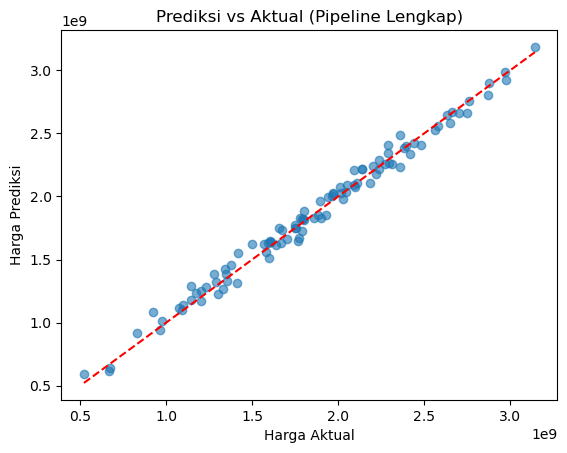

In [8]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Prediksi vs Aktual (Pipeline Lengkap)')
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()